# Experiment 2: Multiple Linear Regression

**Name:** Koushal Gupta  

## Aim
To implement **Multiple Linear Regression** on the real **Stocks dataset** (`stocks.csv`, 105 rows) using `GOOG`, `AMZN`, `FB`, `NFLX`, and `MSFT` to predict `AAPL`.

## Concept
Multiple Linear Regression extends the line equation to multiple inputs:
$$y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_p x_p$$


In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Step 2: Load the small online Stocks dataset (https://raw.githubusercontent.com/plotly/datasets/master/stocks.csv)
df = px.data.stocks()
print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (105, 7)
         date      GOOG      AAPL      AMZN        FB      NFLX      MSFT
0  2018-01-01  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000
1  2018-01-08  1.018172  1.011943  1.061881  0.959968  1.053526  1.015988
2  2018-01-15  1.032008  1.019771  1.053240  0.970243  1.049860  1.020524
3  2018-01-22  1.066783  0.980057  1.140676  1.016858  1.307681  1.066561
4  2018-01-29  1.008773  0.917143  1.163374  1.018357  1.273537  1.040708


In [3]:
# Step 3: Define multiple features (X) and target (y), then split
features = ["GOOG", "AMZN", "FB", "NFLX", "MSFT"]
X = df[features]
y = df["AAPL"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
# Step 4: Train Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))
for feature, coef in zip(features, model.coef_):
    print(f"Coefficient for {feature}: {coef:.4f}")


Intercept: -0.5877
Coefficient for GOOG: 1.3140
Coefficient for AMZN: 0.3161
Coefficient for FB: -0.0275
Coefficient for NFLX: -0.1750
Coefficient for MSFT: 0.1562


In [5]:
# Step 5: Predict and evaluate
y_pred = model.predict(X_test)

print("Mean Squared Error (MSE):", round(mean_squared_error(y_test, y_pred), 4))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))


Mean Squared Error (MSE): 0.0067
R2 Score: 0.8353


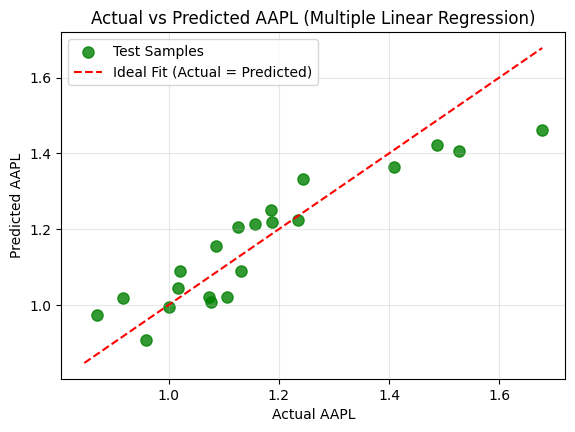

In [6]:
# Step 6: Plot Actual vs Predicted AAPL values
plt.figure(figsize=(6.5, 4.5))
plt.scatter(y_test, y_pred, color="green", s=65, alpha=0.8, label="Test Samples")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Ideal Fit (Actual = Predicted)")
plt.title("Actual vs Predicted AAPL (Multiple Linear Regression)")
plt.xlabel("Actual AAPL")
plt.ylabel("Predicted AAPL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Conclusion
- Using multiple tech stock predictors (`GOOG`, `AMZN`, `FB`, `NFLX`, `MSFT`) improved test $R^2$ from `~0.77` (Experiment 1) to `~0.84`.
- Multiple Linear Regression captures combined market movement across all five stocks.
